# 05 個人權重（方法二）：先分群，再給每群一組權重

原構想的第二種方法：用態度題把人分群，每群一個固定權重。我們做兩個版本：

- **2a 態度分群**：用 K-means 依「家庭價值重要性 8 題＋傳統分工題」（RR2022）與「家庭導向 9 題」（RR2020）分群，**每群的權重用迴歸估計**，不靠目測。
- **2b 潛在類別迴歸（latent class / mixture regression）**：反過來，不先看態度，而是讓 2007–2024 的追蹤資料自己找出「幸福跟著工作走」與「幸福跟著家庭走」的人（DeSarbo & Cron, 1988；Wedel & Kamakura, 2000）。每個人被歸到同一類（跨所有波次），再看態度能不能預測他屬於哪一類。

2b 的意義：如果資料裡真的有「工作型」與「家庭型」兩種人，混合迴歸會把他們分開，而且兩類的工作/家庭斜率比例會很不一樣。

In [1]:
import numpy as np, pandas as pd
import statsmodels.formula.api as smf
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, cross_val_predict
from psfd_utils import *
plt = setup_plot()
main = pd.read_csv(DERIVED / "main_2020_2024.csv", low_memory=False)
long = pd.read_csv(DERIVED / "long_2007_2024.csv", low_memory=False)
att = pd.read_csv(DERIVED / "attitudes_long.csv", low_memory=False)
emp = main[main.employed == 1].dropna(subset=["swb", "jobsat", "famsat", "econsat", "health", "age", "female"]).copy()
for c in ["swb", "jobsat", "famsat", "econsat", "health"]:
    emp[c + "_z"] = emp.groupby("year")[c].transform(z)
CTRL = "econsat_z + health_z + age + I(age**2) + female + web"

## 2a-1 RR2022：用重要性 8 題＋傳統分工題分群

In [2]:
IMP = [f"imp_{i}" for i in range(1, 9)] + ["breadwinner"]
d22 = emp[emp.year == 2022].dropna(subset=IMP).copy()
Xa = ((d22[IMP] - d22[IMP].mean()) / d22[IMP].std()).values
sil = {}
for k in range(2, 7):
    km = KMeans(k, n_init=20, random_state=0).fit(Xa)
    sil[k] = silhouette_score(Xa, km.labels_, sample_size=3000, random_state=0)
print("輪廓係數（越高越好）：", {k: round(v, 3) for k, v in sil.items()})
K = max(sil, key=sil.get)
km = KMeans(K, n_init=20, random_state=0).fit(Xa)
d22["cl"] = km.labels_
prof = d22.groupby("cl")[IMP + ["age", "female", "married", "has_kids"]].mean().round(2)
prof["N"] = d22.cl.value_counts()
prof

輪廓係數（越高越好）： {2: 0.219, 3: 0.193, 4: 0.173, 5: 0.155, 6: 0.144}


,imp_1,imp_2,imp_3,imp_4,imp_5,imp_6,imp_7,imp_8,breadwinner,age,female,married,has_kids,N
cl,,,,,,,,,,,,,,
0,2.32,2.79,4.19,4.07,2.11,3.81,3.85,3.56,2.26,39.22,0.52,0.46,0.45,2010
1,3.68,4.27,4.83,4.81,3.40,4.65,4.64,4.36,2.74,41.92,0.35,0.64,0.63,2352


In [3]:
rows = []
for c, g in d22.groupby("cl"):
    m = smf.ols(f"swb_z ~ jobsat_z + famsat_z + {CTRL}", g).fit(cov_type="HC1")
    rows.append(dict(群=c, N=len(g), 家庭斜率=m.params["famsat_z"], 家庭_se=m.bse["famsat_z"],
                     工作斜率=m.params["jobsat_z"], 工作_se=m.bse["jobsat_z"],
                     家庭權重w=m.params["famsat_z"] / (m.params["famsat_z"] + m.params["jobsat_z"])))
cl22 = pd.DataFrame(rows).round(3)
cl22

,群,N,家庭斜率,家庭_se,工作斜率,工作_se,家庭權重w
0,0,2010,0.266,0.023,0.240,0.020,0.525
1,1,2352,0.302,0.021,0.166,0.023,0.646


In [4]:
# 群間權重差異的正式檢定
d22["clc"] = d22.cl.astype(str)
mfull = smf.ols(f"swb_z ~ (jobsat_z + famsat_z) * C(clc) + {CTRL}", d22).fit()
mred = smf.ols(f"swb_z ~ jobsat_z + famsat_z + C(clc) + {CTRL}", d22).fit()
f_test = mfull.compare_f_test(mred)
print("各群權重是否不同（F 檢定）：F = %.2f, p = %.4f" % (f_test[0], f_test[1]))
print("交叉驗證 R²：每群不同權重 %.4f vs 全體相同權重 %.4f" % (cv_r2(mfull.model.exog, mfull.model.endog)[0], cv_r2(mred.model.exog, mred.model.endog)[0]))

各群權重是否不同（F 檢定）：F = 3.40, p = 0.0333
交叉驗證 R²：每群不同權重 0.3984 vs 全體相同權重 0.3984


## 2a-2 RR2020：用家庭導向 9 題分群

In [5]:
FO = ["mar_a", "mar_b", "mar_c", "mar_d", "mar_f", "mar_g", "gen_b", "gen_c", "gen_d"]
d20 = emp[emp.year == 2020].dropna(subset=FO).copy()
Xb = ((d20[FO] - d20[FO].mean()) / d20[FO].std()).values
sil20 = {k: silhouette_score(Xb, KMeans(k, n_init=20, random_state=0).fit(Xb).labels_, sample_size=3000, random_state=0) for k in range(2, 7)}
print({k: round(v, 3) for k, v in sil20.items()})
K20 = max(sil20, key=sil20.get)
d20["cl"] = KMeans(K20, n_init=20, random_state=0).fit(Xb).labels_
rows = []
for c, g in d20.groupby("cl"):
    m = smf.ols(f"swb_z ~ jobsat_z + famsat_z + {CTRL}", g).fit(cov_type="HC1")
    rows.append(dict(群=c, N=len(g), FO平均=g.fo.mean(), 年齡=g.age.mean(), 家庭斜率=m.params["famsat_z"], 工作斜率=m.params["jobsat_z"],
                     家庭權重w=m.params["famsat_z"] / (m.params["famsat_z"] + m.params["jobsat_z"])))
cl20 = pd.DataFrame(rows).round(3)
cl20

{2: 0.183, 3: 0.149, 4: 0.126, 5: 0.124, 6: 0.128}


,群,N,FO平均,年齡,家庭斜率,工作斜率,家庭權重w
0,0,1806,2.095,36.488,0.282,0.188,0.599
1,1,2243,3.006,41.805,0.262,0.203,0.564


In [6]:
d20["clc"] = d20.cl.astype(str)
mfull = smf.ols(f"swb_z ~ (jobsat_z + famsat_z) * C(clc) + {CTRL}", d20).fit()
mred = smf.ols(f"swb_z ~ jobsat_z + famsat_z + C(clc) + {CTRL}", d20).fit()
f_test = mfull.compare_f_test(mred)
print("各群權重是否不同：F = %.2f, p = %.4f" % (f_test[0], f_test[1]))
print("交叉驗證 R²：每群不同權重 %.4f vs 全體相同權重 %.4f" % (cv_r2(mfull.model.exog, mfull.model.endog)[0], cv_r2(mred.model.exog, mred.model.endog)[0]))

各群權重是否不同：F = 0.69, p = 0.5011
交叉驗證 R²：每群不同權重 0.3975 vs 全體相同權重 0.3981


## 2a-3 對照：用「人生階段」分群（不用任何態度題）

notebook 04 發現「有沒有小孩」會明顯改變權重。若用人生階段（是否有小孩 × 年齡）分群，效果會比態度分群好嗎？

In [7]:
e = emp.dropna(subset=["has_kids"]).copy()
e["stage"] = np.select([(e.has_kids == 0) & (e.age < 40), (e.has_kids == 0) & (e.age >= 40), (e.has_kids == 1) & (e.kid_under6 == 1),
                        (e.has_kids == 1) & (e.youngest_child_age < 18), (e.has_kids == 1)],
                       ["無子女・40 歲以下", "無子女・40 歲以上", "有 6 歲以下子女", "最小子女 6–17 歲", "子女皆成年"], default="其他")
rows = []
for c, g in e.groupby("stage"):
    m = smf.ols(f"swb_z ~ jobsat_z + famsat_z + {CTRL} + C(year)", g).fit(cov_type="cluster", cov_kwds={"groups": g.pid})
    rows.append(dict(人生階段=c, N=len(g), 家庭斜率=m.params["famsat_z"], 家庭_lo=m.conf_int().loc["famsat_z", 0], 家庭_hi=m.conf_int().loc["famsat_z", 1],
                     工作斜率=m.params["jobsat_z"], 工作_lo=m.conf_int().loc["jobsat_z", 0], 工作_hi=m.conf_int().loc["jobsat_z", 1],
                     家庭權重w=m.params["famsat_z"] / (m.params["famsat_z"] + m.params["jobsat_z"])))
stage = pd.DataFrame(rows).set_index("人生階段").loc[["無子女・40 歲以下", "無子女・40 歲以上", "有 6 歲以下子女", "最小子女 6–17 歲", "子女皆成年"]].reset_index()
stage.round(3)

,人生階段,N,家庭斜率,家庭_lo,家庭_hi,工作斜率,工作_lo,工作_hi,家庭權重w
0,無子女・40 歲以下,4323,0.251,0.221,0.280,0.224,0.192,0.256,0.528
1,無子女・40 歲以上,1717,0.241,0.180,0.301,0.238,0.179,0.298,0.503
2,有 6 歲以下子女,2364,0.331,0.287,0.375,0.162,0.125,0.199,0.671
3,最小子女 6–17 歲,3016,0.293,0.254,0.333,0.176,0.139,0.212,0.625
4,子女皆成年,1659,0.366,0.309,0.423,0.149,0.094,0.204,0.711


In [8]:
e["stc"] = e.stage
mfull = smf.ols(f"swb_z ~ (jobsat_z + famsat_z) * C(stc) + {CTRL} + C(year)", e).fit()
mred = smf.ols(f"swb_z ~ jobsat_z + famsat_z + C(stc) + {CTRL} + C(year)", e).fit()
f_test = mfull.compare_f_test(mred)
print("各人生階段權重是否不同：F = %.2f, p = %.6f" % (f_test[0], f_test[1]))
print("交叉驗證 R²：每階段不同權重 %.4f vs 全體相同 %.4f" % (cv_r2(mfull.model.exog, mfull.model.endog)[0], cv_r2(mred.model.exog, mred.model.endog)[0]))

各人生階段權重是否不同：F = 5.53, p = 0.000001
交叉驗證 R²：每階段不同權重 0.3972 vs 全體相同 0.3964


PosixPath('figures/fig05_life_stage.png')

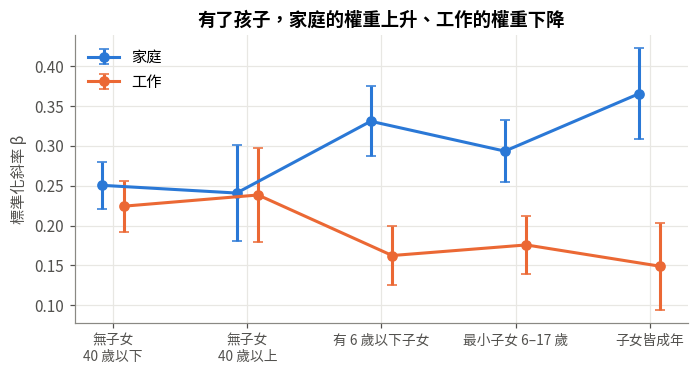

In [9]:
fig, ax = plt.subplots(figsize=(7.2, 3.4))
x = np.arange(len(stage))
ax.errorbar(x - 0.08, stage.家庭斜率, yerr=[stage.家庭斜率 - stage.家庭_lo, stage.家庭_hi - stage.家庭斜率], fmt="o-", color=C_FAMILY, label="家庭", capsize=3)
ax.errorbar(x + 0.08, stage.工作斜率, yerr=[stage.工作斜率 - stage.工作_lo, stage.工作_hi - stage.工作斜率], fmt="o-", color=C_WORK, label="工作", capsize=3)
ax.set_xticks(x, [s.replace("・", "\n") for s in stage.人生階段], fontsize=9)
ax.set_ylabel("標準化斜率 β"); ax.legend(loc="upper left")
ax.set_title("有了孩子，家庭的權重上升、工作的權重下降")
savefig(fig, "fig05_life_stage")

### 2a-4 爸爸與媽媽一樣嗎？人生階段 × 性別

In [10]:
rows = []
for (st, f), g in e.groupby(["stage", "female"]):
    if len(g) < 300: continue
    m = smf.ols(f"swb_z ~ jobsat_z + famsat_z + econsat_z + health_z + age + I(age**2) + web + C(year)", g).fit()
    rows.append(dict(人生階段=st, 性別="女" if f == 1 else "男", N=len(g), 家庭=m.params["famsat_z"], 工作=m.params["jobsat_z"],
                     家庭權重w=m.params["famsat_z"] / (m.params["famsat_z"] + m.params["jobsat_z"])))
sexstage = pd.DataFrame(rows)
sexstage.pivot(index="人生階段", columns="性別", values="家庭權重w").round(3)

性別,女,男
人生階段,,
子女皆成年,0.776,0.655
最小子女 6–17 歲,0.708,0.538
有 6 歲以下子女,0.699,0.640
無子女・40 歲以上,0.502,0.502
無子女・40 歲以下,0.515,0.539


In [11]:
sexstage.round(3)

,人生階段,性別,N,家庭,工作,家庭權重w
0,子女皆成年,男,884,0.373,0.196,0.655
1,子女皆成年,女,775,0.355,0.102,0.776
2,最小子女 6–17 歲,男,1638,0.234,0.200,0.538
3,最小子女 6–17 歲,女,1378,0.357,0.147,0.708
4,有 6 歲以下子女,男,1384,0.312,0.175,0.640
5,有 6 歲以下子女,女,980,0.351,0.151,0.699
6,無子女・40 歲以上,男,1022,0.237,0.235,0.502
7,無子女・40 歲以上,女,695,0.250,0.248,0.502
8,無子女・40 歲以下,男,2474,0.247,0.211,0.539
9,無子女・40 歲以下,女,1849,0.256,0.241,0.515


## 2b 潛在類別迴歸：讓 18 年追蹤資料自己分出「工作型」與「家庭型」

資料：2007–2024 有工作、至少 3 波有效觀測的人。每一波內把幸福（兩題版）、工作、家庭、健康滿意度標準化。
模型：每個人屬於 K 類之一（整段追蹤期間不變），第 k 類的幸福 = a_k + b_k·工作 + c_k·家庭 + d_k·健康 + e_k·年齡 + 誤差（變異數 σ_k²）。
用 EM 演算法估計，K = 1–4，每個 K 用 8 組隨機起始值取最佳，以 BIC 選 K。

In [12]:
L = long[long.employed == 1].dropna(subset=["swb2", "jobsat", "famsat", "health", "age"]).copy()
for c in ["swb2", "jobsat", "famsat", "health"]:
    L[c] = L.groupby("year")[c].transform(z)
cnt = L.groupby("pid").size(); L = L[L.pid.isin(cnt[cnt >= 3].index)]
X = np.column_stack([np.ones(len(L)), L.jobsat, L.famsat, L.health, (L.age - 45) / 10]).astype(float)
y = L.swb2.values.astype(float)
ids, inv = np.unique(L.pid.values, return_inverse=True); n = len(ids)
print("人數", n, "觀測", len(y))


def em(K, seed, iters=500):
    rng = np.random.default_rng(seed)
    R = rng.dirichlet(np.ones(K), n)
    for _ in range(iters):
        B, S, pi = [], [], R.mean(0)
        for k in range(K):
            w = R[inv, k]; Wx = X * w[:, None]
            b = np.linalg.solve(X.T @ Wx + 1e-8 * np.eye(X.shape[1]), Wx.T @ y)
            r = y - X @ b; s = np.sqrt((w * r ** 2).sum() / w.sum())
            B.append(b); S.append(s)
        ll = np.zeros((n, K))
        for k in range(K):
            r = y - X @ B[k]
            ll[:, k] = np.bincount(inv, -0.5 * (r / S[k]) ** 2 - np.log(S[k]) - 0.5 * np.log(2 * np.pi), minlength=n) + np.log(pi[k])
        mx = ll.max(1, keepdims=True); Rn = np.exp(ll - mx); Rn /= Rn.sum(1, keepdims=True)
        if np.abs(Rn - R).max() < 1e-7: R = Rn; break
        R = Rn
    loglik = (mx.ravel() + np.log(np.exp(ll - mx).sum(1))).sum()
    return loglik, np.array(B), np.array(S), R


fits = {}
for K in [1, 2, 3, 4]:
    fits[K] = max((em(K, s) for s in range(8)), key=lambda t: t[0])
    ll, B, S, R = fits[K]
    p = K * (X.shape[1] + 1) + (K - 1)
    print(f"K={K}: logL={ll:.1f}, BIC={-2*ll + p*np.log(len(y)):.1f}")

人數 6018 觀測 39756
K=1: logL=-49452.2, BIC=98967.9


K=2: logL=-46864.2, BIC=93866.0


K=3: logL=-46047.2, BIC=92306.3


K=4: logL=-45728.8, BIC=91743.6


In [13]:
rows = []
for K in [2, 3, 4]:
    ll, B, S, R = fits[K]
    for k in range(K):
        rows.append(dict(K=K, 類別=k + 1, 比例=R.mean(0)[k], 工作斜率=B[k][1], 家庭斜率=B[k][2], 健康斜率=B[k][3],
                         家庭權重w=B[k][2] / (B[k][1] + B[k][2]), 殘差標準差=S[k]))
lc = pd.DataFrame(rows).round(3)
lc

,K,類別,比例,工作斜率,家庭斜率,健康斜率,家庭權重w,殘差標準差
0,2,1,0.507,0.177,0.213,0.198,0.546,0.657
1,2,2,0.493,0.222,0.254,0.208,0.533,0.829
2,3,1,0.217,0.221,0.307,0.218,0.581,0.996
3,3,2,0.341,0.154,0.198,0.182,0.562,0.640
4,3,3,0.442,0.208,0.179,0.197,0.462,0.638
5,4,1,0.452,0.185,0.188,0.196,0.504,0.664
6,4,2,0.137,0.115,0.176,0.137,0.605,0.551
7,4,3,0.222,0.213,0.152,0.169,0.417,0.589
8,4,4,0.190,0.224,0.327,0.230,0.594,1.039


**解讀重點**：如果真的有「工作型」與「家庭型」的人，某一類的家庭權重 w 應該遠低於 0.5、另一類遠高於 0.5。
看上表各類的 w 與殘差標準差：類別之間主要差在「幸福波動的大小」（殘差標準差）與整體斜率高低，而不是工作與家庭的比例。

### 態度能預測一個人屬於哪一類嗎？

In [14]:
ll, B, S, R = fits[3]
w_cls = B[:, 2] / (B[:, 1] + B[:, 2])
fam_type = int(np.argmax(w_cls))         # 家庭權重最高的那一類
pp = pd.DataFrame({"pid": ids, "p_family_type": R[:, fam_type], "cls": R.argmax(1)})
pp["is_family_type"] = (pp.cls == fam_type).astype(int)
a11 = att[att.year == 2011].set_index("pid").mar6.rename("婚姻態度2011")
a20 = att[att.year == 2020].set_index("pid").fo.rename("FO2020")
imp22 = main[main.year == 2022].set_index("pid").fam_importance.rename("重要性2022")
demo = L.groupby("pid").agg(female=("female", "mean"), birth_year=("birth_year", "mean"), kids_share=("has_kids", "mean"))
P = pp.set_index("pid").join([a11, a20, imp22, demo])
for cols in [["婚姻態度2011"], ["FO2020"], ["重要性2022"], ["female", "birth_year", "kids_share"],
             ["婚姻態度2011", "FO2020", "重要性2022", "female", "birth_year", "kids_share"]]:
    q = P.dropna(subset=cols)
    if q.is_family_type.nunique() < 2: continue
    auc = cross_val_score(LogisticRegression(max_iter=1000), (q[cols] - q[cols].mean()) / q[cols].std(), q.is_family_type, cv=5, scoring="roc_auc").mean()
    print(f"{' + '.join(cols):60s} N={len(q):5d}  AUC={auc:.3f}")

婚姻態度2011                                                     N= 3862  AUC=0.481
FO2020                                                       N= 4709  AUC=0.559
重要性2022                                                      N= 4724  AUC=0.485


female + birth_year + kids_share                             N= 6018  AUC=0.558
婚姻態度2011 + FO2020 + 重要性2022 + female + birth_year + kids_share N= 2709  AUC=0.552


AUC = 0.5 代表完全猜不準，1.0 代表完美預測。

In [15]:
cl22.to_csv(DERIVED / "clusters_2022.csv", index=False)
cl20.to_csv(DERIVED / "clusters_2020.csv", index=False)
stage.to_csv(DERIVED / "life_stage_weights.csv", index=False)
lc.to_csv(DERIVED / "latent_class_results.csv", index=False)